## Задание 1

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


In [2]:
class BaseNetwork(nn.Module):
    def __init__(self, act_fn, input_size=784, num_classes=10,
                 hidden_sizes=[512, 256, 256, 128]):
        super().__init__()
        layers = []
        layer_sizes = [input_size] + hidden_sizes
        for i in range(1, len(layer_sizes)):
            layers += [nn.Linear(layer_sizes[i-1], layer_sizes[i]), act_fn]
        layers += [nn.Linear(layer_sizes[-1], num_classes)]
        self.layers = nn.ModuleList(layers)
        self.config = {"act_fn": act_fn.__class__.__name__,
                       "input_size": input_size,
                       "num_classes": num_classes,
                       "hidden_sizes": hidden_sizes}

    def forward(self, x):
        x = x.view(x.size(0), -1)
        for l in self.layers:
            x = l(x)
        return x

In [3]:
def init_constant(m):
    if isinstance(m, nn.Linear):
        nn.init.constant_(m.weight, 0.1)
        nn.init.constant_(m.bias, 0.0)

def init_normal(m):
    if isinstance(m, nn.Linear):
        nn.init.normal_(m.weight, mean=0.0, std=0.05)
        nn.init.constant_(m.bias, 0.0)

def init_xavier(m):
    if isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        nn.init.constant_(m.bias, 0.0)

def init_kaiming(m):
    if isinstance(m, nn.Linear):
        nn.init.kaiming_uniform_(m.weight, nonlinearity='relu')
        nn.init.constant_(m.bias, 0.0)

inits = {
    'constant': init_constant,
    'normal': init_normal,
    'xavier': init_xavier,
    'kaiming': init_kaiming,
}

In [ ]:
def get_activations_and_grads(model, x):
    acts = []
    grads = []
    hooks = []
    for layer in model.layers:
        def hook_forward(module, inp, out, store=acts):
            store.append(out.detach())
        hooks.append(layer.register_forward_hook(hook_forward))

    out = model(x)
    loss = out.sum()
    loss.backward()

    for layer in model.layers:
        if isinstance(layer, nn.Linear):
            g = layer.weight.grad
            grads.append(g.norm().item() if g is not None else 0.0)

    for h in hooks:
        h.remove()
    return acts, grads

In [ ]:
transform = transforms.Compose([transforms.ToTensor()])
train_ds = datasets.FashionMNIST(root='./data', train=True,
                                 download=True, transform=transform)
loader = DataLoader(train_ds, batch_size=64, shuffle=True)
x_batch, _ = next(iter(loader))
x_batch = x_batch.to(device)

activations_map = {'ReLU': nn.ReLU, 'Tanh': nn.Tanh,
                   'Identity': nn.Identity}

for act_name, act_cls in activations_map.items():
    print(f"\n===== Активация: {act_name} =====")
    for init_name, init_fn in inits.items():
        model = BaseNetwork(act_cls()).to(device)
        model.apply(init_fn)
        acts, grads = get_activations_and_grads(model, x_batch)

        act_norms = [a.norm().item() / a.numel()**0.5 for a in acts]
        print(f"  init={init_name:9s} | "
              f"act_norms={[round(v,3) for v in act_norms]} | "
              f"grad_norms={[round(v,4) for v in grads]}")

100%|██████████| 26.4M/26.4M [00:16<00:00, 1.56MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 713kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.92MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]



===== Активация: ReLU =====
  init=constant  | act_norms=[24.563, 24.563, 24.563, 24.563, 24.563, 1257.625, 1257.625, 1257.625, 1257.625, 1257.625, 32194.998, 32194.998, 32194.998, 32194.998, 32194.998, 824195.886, 824195.886, 824195.886, 824195.886, 824195.886, 10549711.817] | grad_norms=[119068408.0, 172330032.0, 243719904.0, 344684768.0, 1743951872.0]
  init=normal    | act_norms=[0.613, 0.43, 0.43, 0.43, 0.43, 0.474, 0.35, 0.35, 0.35, 0.35, 0.28, 0.19, 0.19, 0.19, 0.19, 0.141, 0.093, 0.093, 0.093, 0.093, 0.052] | grad_norms=[143.0471, 161.1733, 195.9642, 208.8421, 181.2244]
  init=xavier    | act_norms=[0.505, 0.356, 0.356, 0.356, 0.356, 0.431, 0.313, 0.313, 0.313, 0.313, 0.316, 0.225, 0.225, 0.225, 0.225, 0.268, 0.186, 0.186, 0.186, 0.186, 0.201] | grad_norms=[552.3056, 530.1949, 591.7335, 598.5701, 371.7581]
  init=kaiming   | act_norms=[0.617, 0.418, 0.418, 0.418, 0.418, 0.583, 0.428, 0.428, 0.428, 0.428, 0.608, 0.387, 0.387, 0.387, 0.387, 0.527, 0.377, 0.377, 0.377, 0.377, 0.5

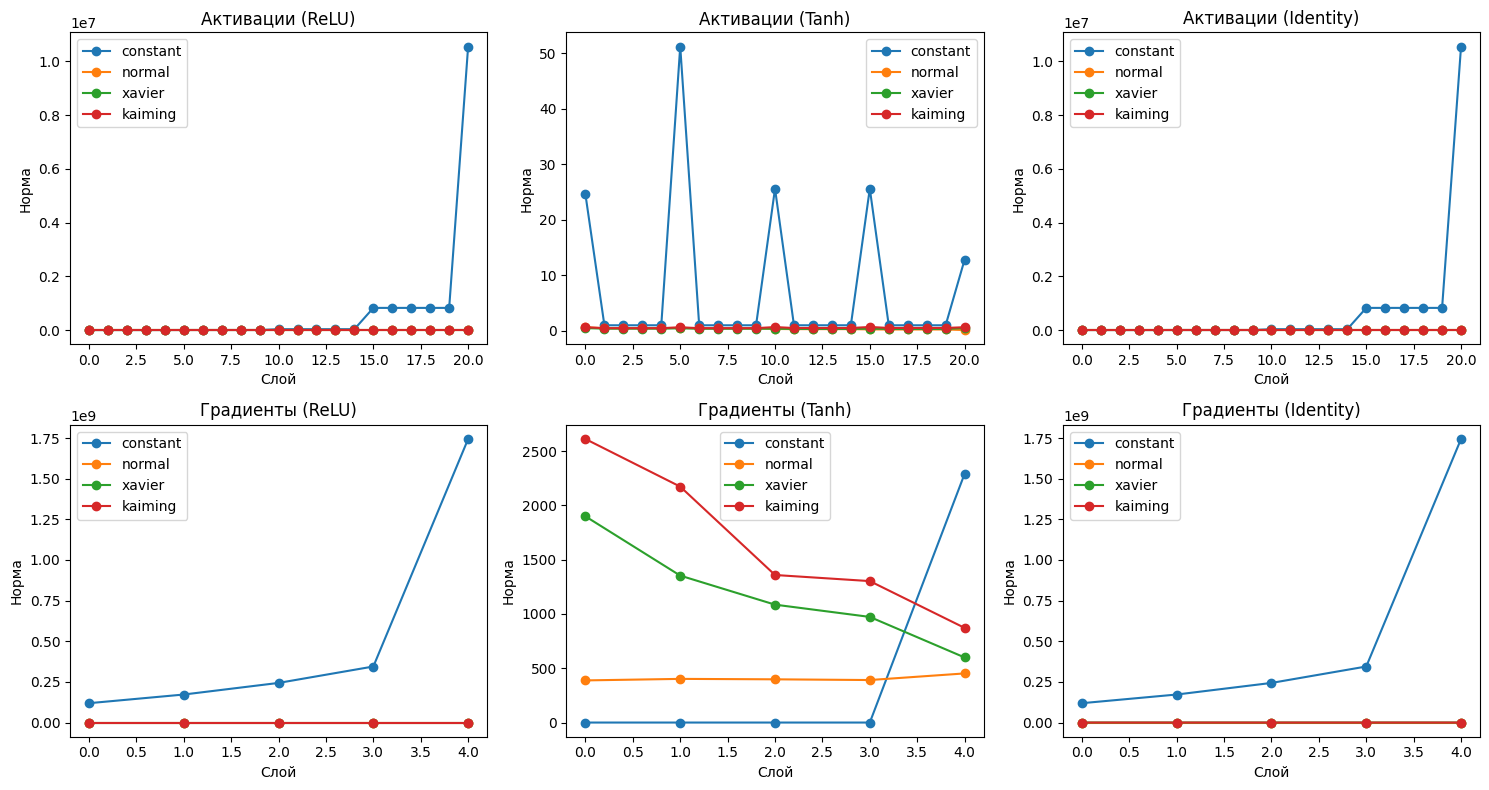

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
acts_names = ['ReLU', 'Tanh', 'Identity']

for j, act_name in enumerate(acts_names):
    for init_name, init_fn in inits.items():
        model = BaseNetwork(activations_map[act_name]()).to(device)
        model.apply(init_fn)
        acts, grads = get_activations_and_grads(model, x_batch)
        act_norms = [a.norm().item() / a.numel()**0.5 for a in acts]
        axes[0, j].plot(act_norms, marker='o', label=init_name)
        axes[1, j].plot(grads, marker='o', label=init_name)
    axes[0, j].set_title(f'Активации ({act_name})')
    axes[1, j].set_title(f'Градиенты ({act_name})')
    axes[0, j].set_xlabel('Слой'); axes[0, j].set_ylabel('Норма')
    axes[1, j].set_xlabel('Слой'); axes[1, j].set_ylabel('Норма')
    axes[0, j].legend(); axes[1, j].legend()
plt.tight_layout(); plt.show()

In [7]:
def train_one(act_cls, init_fn, epochs=3, lr=0.01):
    model = BaseNetwork(act_cls()).to(device)
    model.apply(init_fn)
    opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    crit = nn.CrossEntropyLoss()
    loader = DataLoader(train_ds, batch_size=128, shuffle=True)
    losses = []
    for ep in range(epochs):
        model.train()
        total = 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * xb.size(0)
        losses.append(total / len(train_ds))
        print(f"  {act_cls.__name__}/{init_fn.__name__} ep{ep}: loss={losses[-1]:.4f}")
    return losses

results = {}
for act_cls in [nn.ReLU, nn.Tanh, nn.Identity]:
    for init_name, init_fn in inits.items():
        results[(act_cls.__name__, init_name)] = train_one(act_cls, init_fn)

  ReLU/init_constant ep0: loss=136612677.8819
  ReLU/init_constant ep1: loss=2.3028
  ReLU/init_constant ep2: loss=2.3029
  ReLU/init_normal ep0: loss=0.7872
  ReLU/init_normal ep1: loss=0.4341
  ReLU/init_normal ep2: loss=0.3807
  ReLU/init_xavier ep0: loss=0.6232
  ReLU/init_xavier ep1: loss=0.4006
  ReLU/init_xavier ep2: loss=0.3572
  ReLU/init_kaiming ep0: loss=0.5616
  ReLU/init_kaiming ep1: loss=0.3864
  ReLU/init_kaiming ep2: loss=0.3454
  Tanh/init_constant ep0: loss=2.3251
  Tanh/init_constant ep1: loss=2.3264
  Tanh/init_constant ep2: loss=2.3270
  Tanh/init_normal ep0: loss=0.6519
  Tanh/init_normal ep1: loss=0.4202
  Tanh/init_normal ep2: loss=0.3780
  Tanh/init_xavier ep0: loss=0.5420
  Tanh/init_xavier ep1: loss=0.4014
  Tanh/init_xavier ep2: loss=0.3669
  Tanh/init_kaiming ep0: loss=0.5141
  Tanh/init_kaiming ep1: loss=0.3744
  Tanh/init_kaiming ep2: loss=0.3406
  Identity/init_constant ep0: loss=nan
  Identity/init_constant ep1: loss=nan
  Identity/init_constant ep2: lo

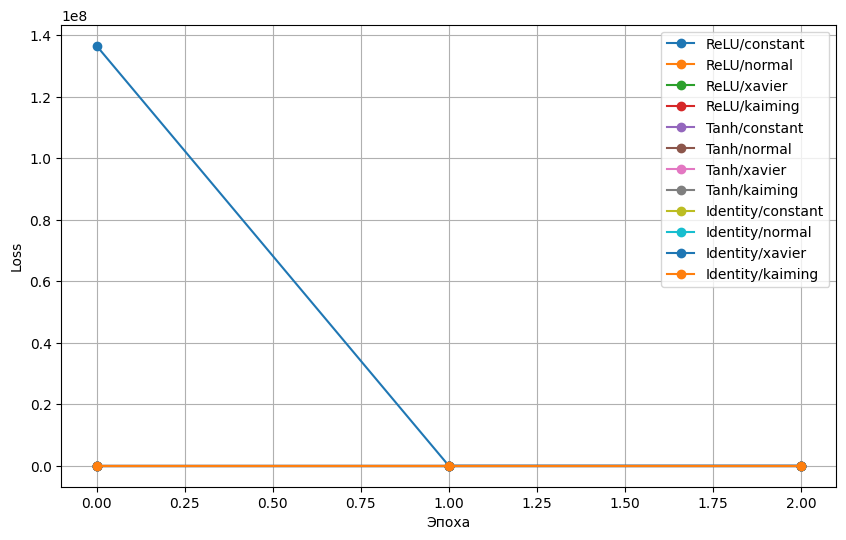

In [ ]:
plt.figure(figsize=(10, 6))
for (act, init), losses in results.items():
    plt.plot(losses, marker='o', label=f'{act}/{init}')
plt.xlabel('Эпоха'); plt.ylabel('Loss')
plt.legend(); plt.grid(); plt.show()

In [8]:
leaky_results = train_one(lambda: nn.LeakyReLU(0.1), init_kaiming)

  <lambda>/init_kaiming ep0: loss=0.5551
  <lambda>/init_kaiming ep1: loss=0.3857
  <lambda>/init_kaiming ep2: loss=0.3415


## Задание 2

In [ ]:
class Node:
    def __init__(self, data, _children=(), _op=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op

    def __repr__(self):
        return f"Node(data={self.data}, grad={self.grad})"

    def __add__(self, other):
        other = other if isinstance(other, Node) else Node(other)
        out = Node(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad  += out.grad
            other.grad += out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Node) else Node(other)
        out = Node(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad  += other.data * out.grad
            other.grad += self.data  * out.grad
        out._backward = _backward
        return out

    def relu(self):
        out = Node(max(0.0, self.data), (self,), 'relu')

        def _backward():
            self.grad += (1.0 if out.data > 0 else 0.0) * out.grad
        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()

        def build(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build(child)
                topo.append(v)

        build(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [11]:
a = Node(2)
b = Node(-3)
c = Node(10)
d = a + b * c
e = d.relu()
e.backward()
print(a, b, c, d, e)

Node(data=2, grad=0.0) Node(data=-3, grad=0.0) Node(data=10, grad=0.0) Node(data=-28, grad=0.0) Node(data=0.0, grad=1.0)


In [ ]:
import unittest

class TestNode(unittest.TestCase):

    def test_add(self):
        a = Node(2.0); b = Node(3.0)
        c = a + b
        c.backward()
        self.assertEqual(c.data, 5.0)
        self.assertEqual(a.grad, 1.0)
        self.assertEqual(b.grad, 1.0)

    def test_mul(self):
        a = Node(2.0); b = Node(3.0)
        c = a * b
        c.backward()
        self.assertEqual(c.data, 6.0)
        self.assertEqual(a.grad, 3.0)
        self.assertEqual(b.grad, 2.0)

    def test_add_const(self):
        a = Node(2.0)
        c = a + 5
        c.backward()
        self.assertEqual(c.data, 7.0)
        self.assertEqual(a.grad, 1.0)

    def test_mul_const(self):
        a = Node(2.0)
        c = a * 5
        c.backward()
        self.assertEqual(c.data, 10.0)
        self.assertEqual(a.grad, 5.0)

    def test_relu_pos(self):
        a = Node(2.0)
        b = a.relu()
        b.backward()
        self.assertEqual(b.data, 2.0)
        self.assertEqual(a.grad, 1.0)

    def test_relu_neg(self):
        a = Node(-2.0)
        b = a.relu()
        b.backward()
        self.assertEqual(b.data, 0.0)
        self.assertEqual(a.grad, 0.0)

    def test_shared_node(self):
        x = Node(3.0)
        y = x + x
        y.backward()
        self.assertEqual(y.data, 6.0)
        self.assertEqual(x.grad, 2.0)

    def test_chain(self):
        a = Node(2.0); b = Node(-3.0); c = Node(10.0)
        d = a + b * c
        e = d.relu()
        e.backward()
        self.assertEqual(d.data, -28.0)
        self.assertEqual(e.data, 0.0)
        self.assertEqual(a.grad, 0.0)
        self.assertEqual(b.grad, 0.0)
        self.assertEqual(c.grad, 0.0)

    def test_chain_relu_pos(self):
        a = Node(2.0); b = Node(3.0)
        d = a * b
        e = d.relu()
        e.backward()
        self.assertEqual(d.data, 6.0)
        self.assertEqual(a.grad, 3.0)
        self.assertEqual(b.grad, 2.0)

unittest.main(argv=['first-arg-is-ignored'], exit=False)

.........
----------------------------------------------------------------------
Ran 9 tests in 0.015s

OK


## Задание 3

In [13]:
class MyMomentum:
    def __init__(self, params, lr=0.01, momentum=0.9):
        self.params = list(params)
        self.lr = lr
        self.momentum = momentum
        self.velocities = [torch.zeros_like(p) for p in self.params]

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()

    def step(self):
        for i, p in enumerate(self.params):
            if p.grad is None:
                continue
            self.velocities[i] = self.momentum * self.velocities[i] + p.grad
            p.data -= self.lr * self.velocities[i]

In [14]:
class MyAdam:
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        self.params = list(params)
        self.lr = lr
        self.b1, self.b2 = betas
        self.eps = eps
        self.m = [torch.zeros_like(p) for p in self.params]
        self.v = [torch.zeros_like(p) for p in self.params]
        self.t = 0

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()

    def step(self):
        self.t += 1
        for i, p in enumerate(self.params):
            if p.grad is None:
                continue
            g = p.grad
            self.m[i] = self.b1 * self.m[i] + (1 - self.b1) * g
            self.v[i] = self.b2 * self.v[i] + (1 - self.b2) * g * g

            m_hat = self.m[i] / (1 - self.b1 ** self.t)
            v_hat = self.v[i] / (1 - self.b2 ** self.t)

            p.data -= self.lr * m_hat / (v_hat.sqrt() + self.eps)

In [ ]:
def test_optimizer(opt_cls, name):
    torch.manual_seed(0)
    w = torch.nn.Parameter(torch.tensor([3.0, -2.0]))
    opt = opt_cls([w], lr=0.1)
    target = torch.tensor([1.0, 1.0])

    losses = []
    for _ in range(200):
        opt.zero_grad()
        loss = ((w - target) ** 2).sum()
        loss.backward()
        opt.step()
        losses.append(loss.item())

    print(f"{name}: start={losses[0]:.4f}, end={losses[-1]:.6f}")
    assert losses[-1] < losses[0], f"{name} не уменьшает лосс"
    assert losses[-1] < 1e-3, f"{name} плохо сходится"

test_optimizer(MyMomentum, 'Momentum')
test_optimizer(MyAdam, 'Adam')

Momentum: start=13.0000, end=0.000000
Adam: start=13.0000, end=0.000000


In [ ]:
def train_with_opt(opt_cls, opt_kwargs, epochs=3):
    model = BaseNetwork(nn.ReLU()).to(device)
    model.apply(init_kaiming)
    opt = opt_cls(model.parameters(), **opt_kwargs)
    crit = nn.CrossEntropyLoss()
    loader = DataLoader(train_ds, batch_size=128, shuffle=True)

    for ep in range(epochs):
        model.train()
        total = 0
        grad_norm_sum = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()

            gn = sum(p.grad.norm().item() ** 2 for p in model.parameters()
                     if p.grad is not None) ** 0.5
            grad_norm_sum += gn

            opt.step()
            total += loss.item() * xb.size(0)

        all_w = torch.cat([p.data.flatten() for p in model.parameters()])
        print(f"{opt_cls.__name__} ep{ep}: loss={total/len(train_ds):.4f}, "
              f"avg||g||={grad_norm_sum/len(loader):.4f}, "
              f"w_mean={all_w.mean():.4f}, w_std={all_w.std():.4f}")

train_with_opt(MyMomentum, {'lr': 0.01, 'momentum': 0.9})
train_with_opt(MyAdam,     {'lr': 1e-3})

MyMomentum ep0: loss=0.5659, avg||g||=2.2568, w_mean=-0.0000, w_std=0.0611
MyMomentum ep1: loss=0.3816, avg||g||=1.7217, w_mean=-0.0001, w_std=0.0613
MyMomentum ep2: loss=0.3432, avg||g||=1.6548, w_mean=-0.0002, w_std=0.0615
MyAdam ep0: loss=0.4889, avg||g||=2.1224, w_mean=-0.0018, w_std=0.0633
MyAdam ep1: loss=0.3562, avg||g||=1.3463, w_mean=-0.0029, w_std=0.0654
MyAdam ep2: loss=0.3201, avg||g||=1.1746, w_mean=-0.0037, w_std=0.0676


In [17]:
def train_reference(opt_cls, opt_kwargs, epochs=3):
    model = BaseNetwork(nn.ReLU()).to(device)
    model.apply(init_kaiming)
    opt = opt_cls(model.parameters(), **opt_kwargs)
    crit = nn.CrossEntropyLoss()
    loader = DataLoader(train_ds, batch_size=128, shuffle=True)

    for ep in range(epochs):
        model.train()
        total = 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * xb.size(0)
        print(f"[torch] {opt_cls.__name__} ep{ep}: loss={total/len(train_ds):.4f}")

train_reference(optim.SGD,  {'lr': 0.01, 'momentum': 0.9})
train_reference(optim.Adam, {'lr': 1e-3})

[torch] SGD ep0: loss=0.5606
[torch] SGD ep1: loss=0.3813
[torch] SGD ep2: loss=0.3437
[torch] Adam ep0: loss=0.4889
[torch] Adam ep1: loss=0.3564
[torch] Adam ep2: loss=0.3223


## Задание 4

In [2]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [7]:
EPOCHS, LR = 25, 5e-4
AUX_WEIGHT = 0.3

for f in ['submission.csv']:
    if os.path.exists(f): os.remove(f)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [8]:
train_x = pd.read_csv('train_x.csv'); train_y = pd.read_csv('train_y.csv'); test_x = pd.read_csv('test_x.csv')
X_all_raw = train_x.iloc[:, 1:].values.astype(np.float32)
y_all = train_y.iloc[:, -1].values.astype(np.float32)
test_ids = test_x['id'].values
X_test_raw = test_x.iloc[:, :-1].values.astype(np.float32)
X_all_raw = np.nan_to_num(X_all_raw, nan=0., posinf=0., neginf=0.)
X_test_raw = np.nan_to_num(X_test_raw, nan=0., posinf=0., neginf=0.)

def add_features(X):
    feats = [X]
    feats.append(np.linalg.norm(X, axis=1, keepdims=True))
    feats.append(X[:, :45].mean(axis=1, keepdims=True))
    feats.append(X[:, 45:].mean(axis=1, keepdims=True))
    feats.append(X[:, :45].std(axis=1, keepdims=True))
    feats.append(X[:, 45:].std(axis=1, keepdims=True))
    feats.append(X[:, :30].mean(axis=1, keepdims=True))
    feats.append(X[:, 30:60].mean(axis=1, keepdims=True))
    feats.append(X[:, 60:].mean(axis=1, keepdims=True))
    for i in range(3):
        for j in range(i+1, 5):
            feats.append((X[:, i] * X[:, j]).reshape(-1, 1))
    for i in range(5):
        feats.append((X[:, i] ** 2).reshape(-1, 1))
    return np.concatenate(feats, axis=1).astype(np.float32)

print("FE: базовый")
X_all = add_features(X_all_raw); X_test = add_features(X_test_raw)
print(f"X: {X_all_raw.shape} -> {X_all.shape}")

FE: базовый
X: (14000, 90) -> (14000, 112)


In [9]:
y_decades = np.clip((y_all // 10 - 192), 0, 9).astype(np.int64)
print(f"Декады: {np.bincount(y_decades, minlength=10)}")

y_mean = y_all.mean(); y_std = y_all.std()
y_norm = (y_all - y_mean) / y_std

X_tr, X_val, y_tr_y, y_val_y, y_tr_d, y_val_d = train_test_split(
    X_all, y_norm, y_decades, test_size=0.2, random_state=42
)

scaler = QuantileTransformer(n_quantiles=1000, output_distribution='normal', random_state=42)
X_tr = scaler.fit_transform(X_tr)
X_val = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)
lo, hi = X_tr.min(0), X_tr.max(0)
X_val = np.clip(X_val, lo, hi); X_test_scaled = np.clip(X_test_scaled, lo, hi)

X_tr = torch.tensor(X_tr, dtype=torch.float32)
y_tr_y_t = torch.tensor(y_tr_y, dtype=torch.float32).unsqueeze(1)
y_tr_d_t = torch.tensor(y_tr_d, dtype=torch.long)
X_val = torch.tensor(X_val, dtype=torch.float32)
y_val_y_t = torch.tensor(y_val_y, dtype=torch.float32).unsqueeze(1)
y_val_d_t = torch.tensor(y_val_d, dtype=torch.long)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_tr, y_tr_y_t, y_tr_d_t), batch_size=512, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val, y_val_y_t, y_val_d_t), batch_size=1024)

Декады: [   8    5   15   89  308  688 1133 3388 8115  251]


In [ ]:
class HybridNet(nn.Module):
    def __init__(self, in_dim, n_decades=10):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Linear(in_dim, 256), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64), nn.ReLU(),
        )
        self.head_reg = nn.Linear(64, 1)
        self.head_cls = nn.Linear(64, n_decades)

    def forward(self, x):
        h = self.backbone(x)
        return self.head_reg(h), self.head_cls(h)

class MyAdam:
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        self.params = list(params); self.lr = lr; self.b1, self.b2 = betas; self.eps = eps
        self.m = [torch.zeros_like(p) for p in self.params]
        self.v = [torch.zeros_like(p) for p in self.params]
        self.t = 0
    def zero_grad(self):
        for p in self.params:
            if p.grad is not None: p.grad.zero_()
    def step(self):
        self.t += 1
        for i, p in enumerate(self.params):
            if p.grad is None: continue
            g = p.grad
            self.m[i] = self.b1*self.m[i] + (1-self.b1)*g
            self.v[i] = self.b2*self.v[i] + (1-self.b2)*g*g
            m_hat = self.m[i]/(1-self.b1**self.t); v_hat = self.v[i]/(1-self.b2**self.t)
            p.data -= self.lr*m_hat/(v_hat.sqrt()+self.eps)

def train_hybrid(model, epochs=EPOCHS, lr=LR, patience=6):
    opt = MyAdam(model.parameters(), lr=lr)
    mse = nn.MSELoss()
    ce = nn.CrossEntropyLoss(label_smoothing=0.05)
    best_val = float('inf'); best_state = None; no_imp = 0

    for ep in range(epochs):
        model.train(); tl = 0.
        for xb, yb_y, yb_d in train_loader:
            xb = xb.to(device); yb_y = yb_y.to(device); yb_d = yb_d.to(device)
            opt.zero_grad()
            pred_y, logits_d = model(xb)
            loss = mse(pred_y, yb_y) + AUX_WEIGHT * ce(logits_d, yb_d)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tl += loss.item() * xb.size(0)
        tl /= len(train_loader.dataset)

        model.eval(); vm = 0.
        with torch.no_grad():
            for xb, yb_y, _ in val_loader:
                xb = xb.to(device); yb_y = yb_y.to(device)
                pred_y, _ = model(xb)
                vm += ((pred_y - yb_y) ** 2).sum().item()
        vm /= len(val_loader.dataset)

        if vm < best_val - 1e-4:
            best_val = vm; best_state = {k: v.clone() for k, v in model.state_dict().items()}; no_imp = 0
        else:
            no_imp += 1
        if ep % 3 == 0 or ep == epochs - 1:
            print(f"  ep{ep:02d}: train_loss={tl:.4f}, val_MSE={vm * y_std**2:.2f}")
        if no_imp >= patience:
            print(f"  Early stop at ep{ep}")
            break
    if best_state is not None: model.load_state_dict(best_state)
    return best_val

torch.manual_seed(42); np.random.seed(42)
model = HybridNet(X_all.shape[1]).to(device)
best_v = train_hybrid(model)
best_v_years = best_v * (y_std ** 2)
print(f"\nVal MSE (годы): {best_v_years:.2f}")

  ep00: train_loss=1.5982, val_MSE=104.09
  ep03: train_loss=1.1027, val_MSE=84.37
  ep06: train_loss=1.0231, val_MSE=82.21
  ep09: train_loss=0.9723, val_MSE=80.80
  ep12: train_loss=0.9177, val_MSE=80.57
  ep15: train_loss=0.8722, val_MSE=81.71
  Early stop at ep17

Val MSE (годы): 79.73


In [11]:
def predict_years(model, X_tensor):
    model.eval()
    with torch.no_grad():
        pred_y, _ = model(X_tensor.to(device))
        return pred_y.cpu().numpy().flatten() * y_std + y_mean

y_val_real = np.asarray(y_val_y).flatten() * y_std + y_mean
y_val_pred = predict_years(model, X_val)
mse_years = mean_squared_error(y_val_real, y_val_pred)
mae_years = mean_absolute_error(y_val_real, y_val_pred)
print(f"Val MSE (годы): {mse_years:.2f}, MAE: {mae_years:.2f}")

Val MSE (годы): 79.73, MAE: 6.18


In [12]:
test_pred = predict_years(model, X_test_t)
test_pred = np.clip(np.nan_to_num(test_pred, nan=2000., posinf=2011., neginf=1922.), 1922, 2011)
test_pred_int = np.round(test_pred).astype(int)
sub = pd.DataFrame({'id': test_ids, 'year': test_pred_int})
sub.to_csv('submission.csv', index=False)
print("\nСабмит:", sub.shape, sub['year'].min(), sub['year'].max())


Сабмит: (6000, 2) 1973 2010
